In [26]:
import numpy as np
import matplotlib.pyplot as plt

# 面积：单位为 100 平方米
x_train = np.array([0.5, 0.8, 1.0, 1.2, 1.5, 1.8, 2.0])

# 价格：单位为万元
y_train = np.array([110, 155, 205, 235, 310, 355, 410])

In [27]:
def predict(x, w, b):
     
     return w * x + b


def compute_cost(x, y, w, b):
    m = len(x)

    predictions = predict(x, w, b)
    
    cost = sum((predictions - y) ** 2) / (2 * m)
    
    return cost

In [28]:
y = np.array([110, 155, 205, 235, 310, 355, 410])
x = np.array([0.5, 0.8, 1.0, 1.2, 1.5, 1.8, 2.0])
w=200
b=0
print(predict(x, w, b))
print(compute_cost(x, y, w, b))


[100. 160. 200. 240. 300. 360. 400.]
28.571428571428573


In [29]:
def compute_gradient(x, y, w, b):
    m = len(x)
    dj_dw = 0.0
    dj_db = 0.0

    for i in range(m):
        error = predict(x[i], w, b) - y[i]

        dj_dw += error * x[i]
        dj_db += error

    return dj_dw / m, dj_db / m



def gradient_descent(x, y, w, b, alpha, iterations):
    cost_history = []

    for i in range(iterations):
        dj_dw, dj_db = compute_gradient(x, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        cost = compute_cost(x, y, w, b)
        cost_history.append(cost)

    return w, b, cost_history

In [30]:
w, b, history = gradient_descent(
    x_train, y_train,
    w=0.0,
    b=0.0,
    alpha=0.1,
    iterations=2000,
)

print("w =", w)
print("b =", b)
print("最终代价 =", history[-1])
print("130 平方米的预测价格 =", predict(1.3, w, b))

w = 200.48780419261834
b = 2.243903387618204
最终代价 = 24.459930313588966
130 平方米的预测价格 = 262.8780488380221


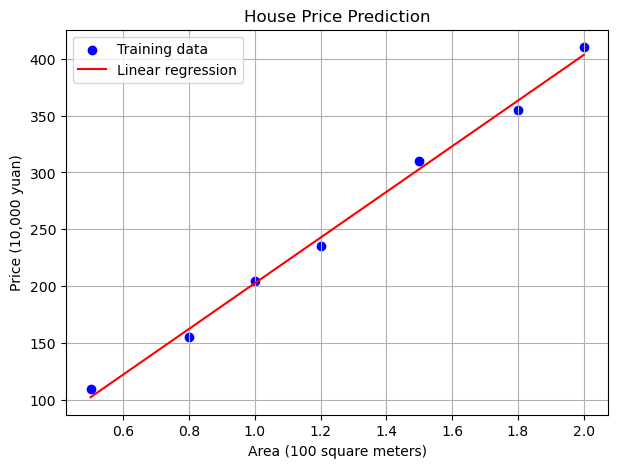

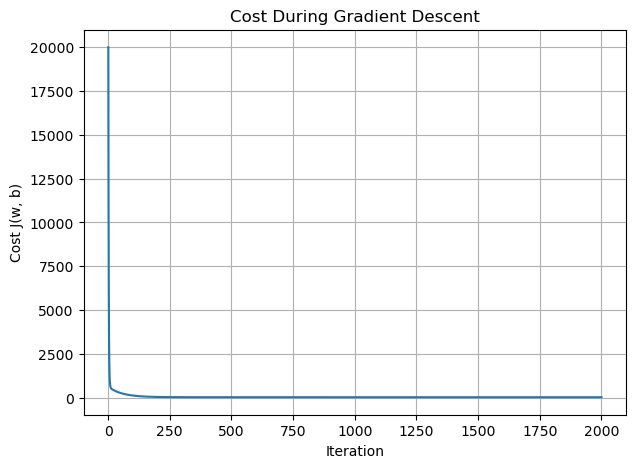

In [31]:
import matplotlib.pyplot as plt

# 第一张图：真实数据和拟合直线
y_pred = predict(x_train, w, b)

plt.figure(figsize=(7, 5))
plt.scatter(x_train, y_train, color="blue", label="Training data")
plt.plot(x_train, y_pred, color="red", label="Linear regression")

plt.xlabel("Area (100 square meters)")
plt.ylabel("Price (10,000 yuan)")
plt.title("House Price Prediction")
plt.legend()
plt.grid(True)
plt.show()


# 第二张图：代价随迭代次数的变化
plt.figure(figsize=(7, 5))
plt.plot(range(1, len(history) + 1), history)

plt.xlabel("Iteration")
plt.ylabel("Cost J(w, b)")
plt.title("Cost During Gradient Descent")
plt.grid(True)
plt.show()